In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [157]:
import sys
from pathlib import Path

# Identifica a raiz do projeto
BASE_DIR = Path.cwd().parent

# Adiciona a raiz do projeto ao caminho de importação
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

print("Raiz do projeto:", BASE_DIR)

Raiz do projeto: c:\Users\dyego\Documents\Projetos\Olist Brazilian E-Commerce Dataset


In [158]:
import sys

print(sys.path)

['c:\\Users\\dyego\\Documents\\Projetos\\Olist Brazilian E-Commerce Dataset', 'C:\\Python312\\python312.zip', 'C:\\Python312\\DLLs', 'C:\\Python312\\Lib', 'C:\\Python312', 'c:\\Users\\dyego\\Documents\\Projetos\\Olist Brazilian E-Commerce Dataset\\.venv', '', 'c:\\Users\\dyego\\Documents\\Projetos\\Olist Brazilian E-Commerce Dataset\\.venv\\Lib\\site-packages']


In [159]:
from src.database import engine

In [160]:
consulta = 'select * from analytics.orders;'

df_orders = pd.read_sql(consulta, con=engine)

df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [161]:
df_orders.shape

(99441, 8)

In [162]:
consulta = 'select * from analytics.order_items;'

df_items = pd.read_sql(consulta, con=engine)

df_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [163]:
df_items.shape

(112650, 7)

In [164]:
print(f'valores de tabela "orders"[order_id] duplicados: {df_orders['order_id'].duplicated().sum()}')
print(f'valores da tabela "order_items"[order_id] unicos: {df_items['order_id'].nunique()}')

valores de tabela "orders"[order_id] duplicados: 0
valores da tabela "order_items"[order_id] unicos: 98666


In [165]:
df_orders_delivered = df_orders[df_orders['order_status'] == 'delivered'] 
df_orders_delivered.shape

(96478, 8)

### merge() -> Criação de df_vendas, contendo somente os items associados a pedidos entregues

In [166]:
# União de dataframe 
df_vendas = pd.merge(df_orders_delivered, df_items, on= "order_id", how='inner', validate='one_to_many')
df_vendas.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [167]:
df_vendas.shape

(110197, 14)

In [168]:
# Pedidos unicos
unicos = df_vendas['order_id'].nunique()
unicos


96478

### Indicadores Comerciais


In [169]:
# Calculo de total de produtos vendidos, sem frete
total_vendas = df_vendas['price'].sum()
print(f'Valor total de venda sem frete: {total_vendas:,.2f}')
# Calculo de total de frete do produtos vendidos, sem valor de venda
total_frete = df_vendas['freight_value'].sum()
print(f'Valor total de frete: {total_frete:,.2f}')
# Calculo de total arrecadado com vendas
print(f'Valor total arrecadado com vendas: {(total_vendas + total_frete):,.2f}')

Valor total de venda sem frete: 13,221,498.11
Valor total de frete: 2,198,275.64
Valor total arrecadado com vendas: 15,419,773.75


In [170]:
# Ticket Médio

ticket_medio = (total_vendas + total_frete) / unicos
print(f'Ticket Médio = {ticket_medio:,.2f}')

Ticket Médio = 159.83


### Evolução mensal das vendas

In [171]:
df_vendas['order_purchase_timestamp'].dtype

df_vendas['ano_mes'] = df_vendas['order_purchase_timestamp'].dt.to_period('M')
df_vendas.head()
df_vendas.shape

(110197, 15)

In [172]:
# Agrupamento -> Valor de vendas por mês
vendas_mensais = df_vendas.groupby('ano_mes')['price'].sum()
print(vendas_mensais.map(lambda valor: f'{valor:,.2f}').head())
print(type(vendas_mensais))

ano_mes
2016-09        134.97
2016-10     40,325.11
2016-12         10.90
2017-01    111,798.36
2017-02    234,223.40
Freq: M, Name: price, dtype: str
<class 'pandas.Series'>


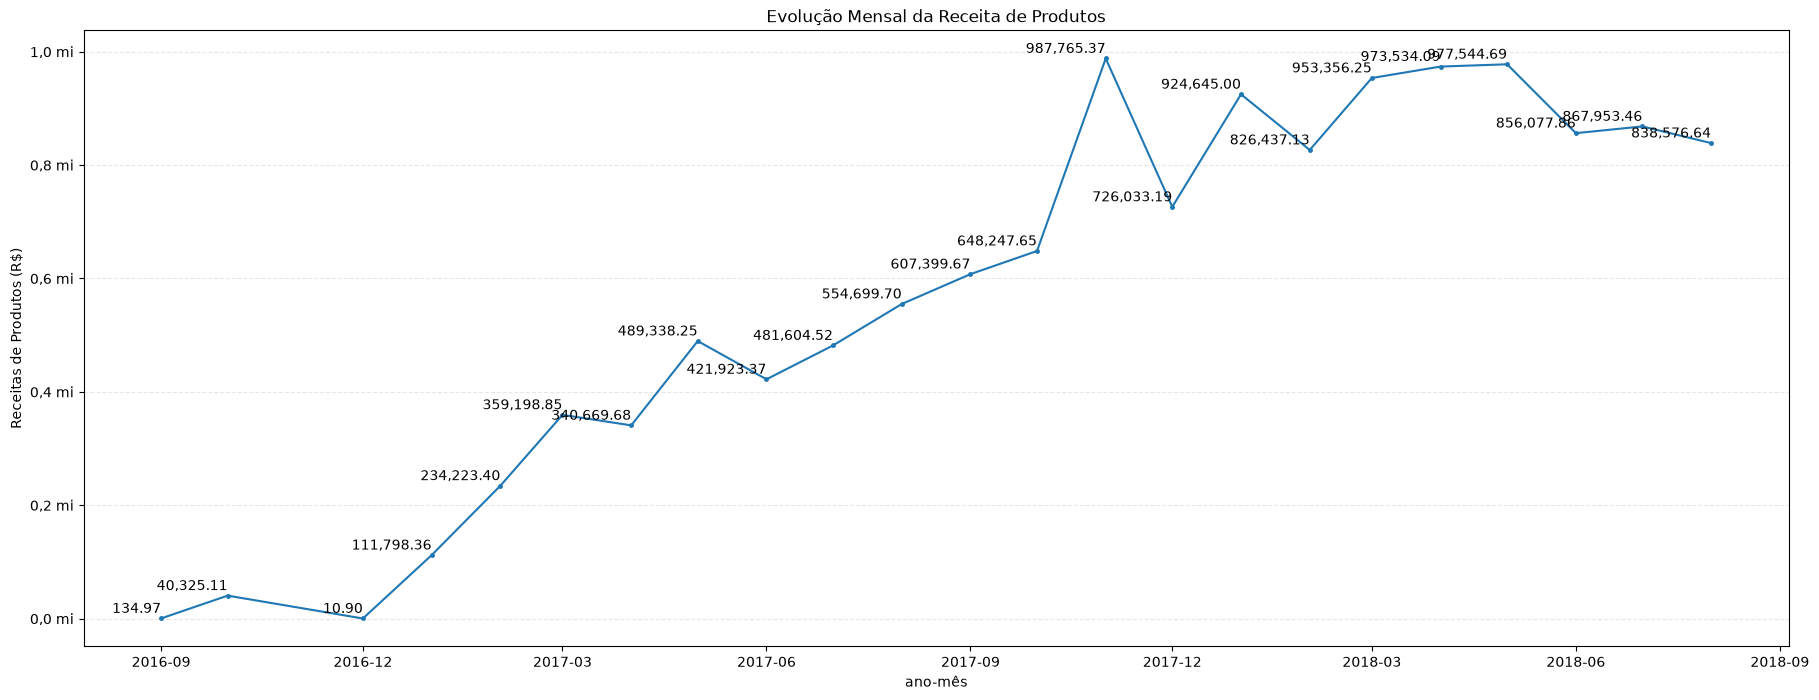

In [173]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Formatador de datas
formatador = mdates.DateFormatter('%Y-%m')
localizador = mdates.MonthLocator(interval=3)

# Formatador de valores
formatador_valores = FuncFormatter(lambda valor, posicao: f'{valor /1_000_000:.1f} mi'.replace('.',','))


# Plotando
plt.figure(figsize=(22,8))
plt.title('Evolução Mensal da Receita de Produtos')
plt.plot(vendas_mensais.index.to_timestamp(), vendas_mensais.values, marker= '.', markersize=5)
plt.xlabel('ano-mês')
plt.ylabel('Receitas de Produtos (R$)')
plt.gca().xaxis.set_major_locator(localizador)
plt.gca().xaxis.set_major_formatter(formatador)
plt.gca().yaxis.set_major_formatter(formatador_valores)
for mes, receita in zip(vendas_mensais.index.to_timestamp(), vendas_mensais.values):
    plt.annotate(
        text= str(f'{receita:,.2f}') ,
        xy = (mes, receita),
        xytext=(0,4),
        textcoords='offset points',
        ha = 'right'
    )
plt.grid(axis='y', linestyle = '--', alpha = 0.3)
plt.show()

In [174]:
df_vendas['order_purchase_timestamp'].dtype

df_vendas['ano_mes'] = df_vendas['order_purchase_timestamp'].dt.to_period('M')
df_vendas.head()
df_vendas.shape

(110197, 15)

In [175]:
maior_receita = vendas_mensais.max()
mes_maior_receita = vendas_mensais.idxmax()
mes_maior_receita = mes_maior_receita.to_timestamp()

def formatar_valor(valor):
    return f'R$ {valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

print(f'Maior receita: {formatar_valor(maior_receita)}')
print(f'Mês de Maior receita: {mes_maior_receita}')

Maior receita: R$ 987.765,37
Mês de Maior receita: 2017-11-01 00:00:00


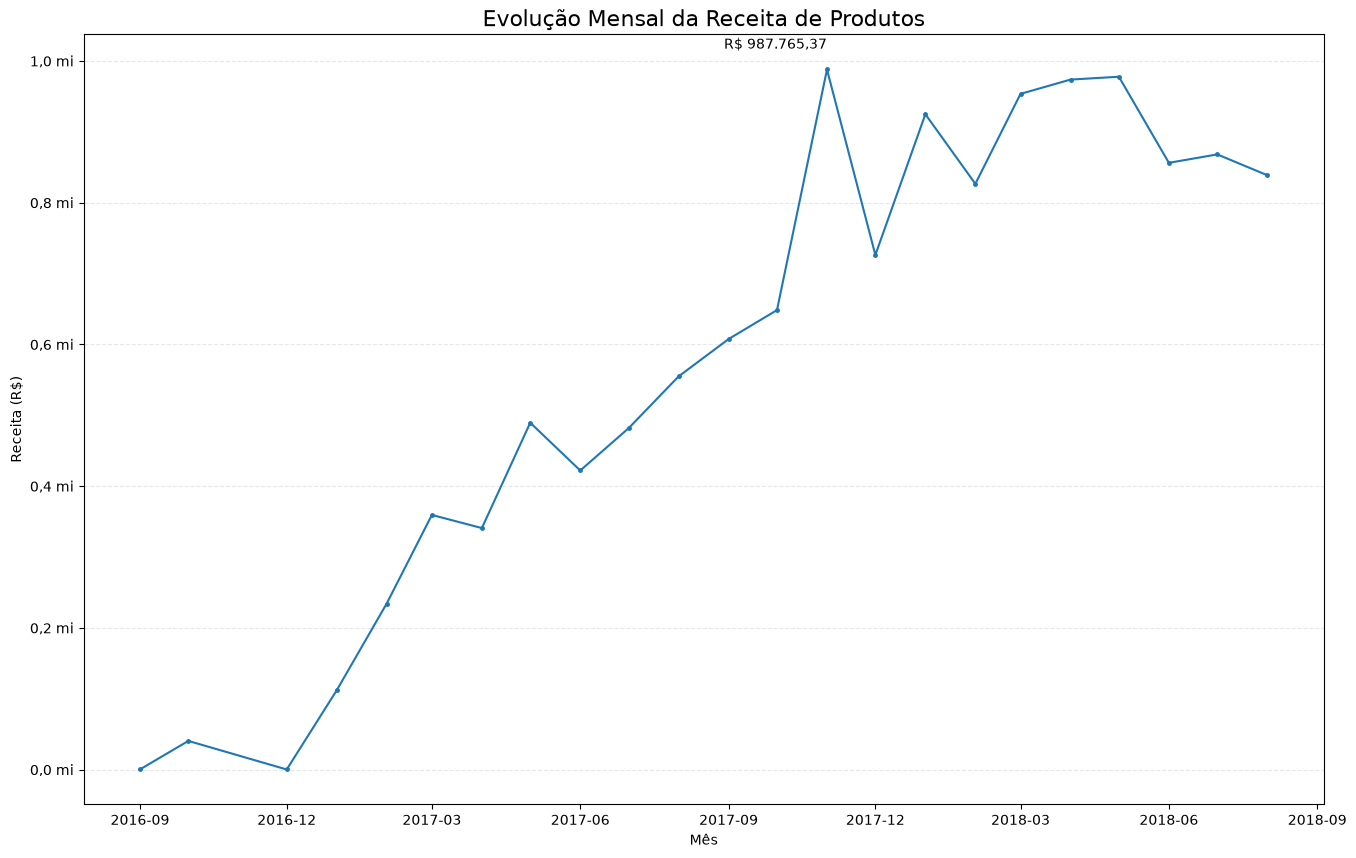

In [176]:
plt.figure(figsize=(16,10))
plt.title('Evolução Mensal da Receita de Produtos', ha='center', fontsize=16)
plt.plot(vendas_mensais.index.to_timestamp(), vendas_mensais.values, marker= '.', markersize=5)
plt.xlabel('Mês')
plt.ylabel('Receita (R$)')
plt.gca().xaxis.set_major_locator(localizador)
plt.gca().xaxis.set_major_formatter(formatador)
plt.gca().yaxis.set_major_formatter(formatador_valores)
plt.annotate(
        text=formatar_valor(maior_receita),
        xy = (mes_maior_receita, maior_receita),
        xytext=(0,15),
        textcoords='offset points',
        ha = 'right'
    )
plt.grid(axis='y', linestyle = '--', alpha = 0.3)
plt.show()

### Quais são as 10 categorias com maior receita?

* identificar as categorias de produtos que mais contribuem para a receita de itens dos pedidos entregues.

In [177]:
consulta = 'select * from analytics.products;'

df_products = pd.read_sql(consulta, con=engine)

df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [178]:
print(df_products.shape)
print(df_products.info())

(32951, 9)
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB
None


In [179]:

df_vendas_produtos = pd.merge(df_vendas, df_products[['product_id', 'product_category_name']],
                              on= 'product_id', how='left', validate='many_to_one')

In [180]:
df_vendas_produtos.shape

(110197, 16)

In [181]:
df_vendas_produtos.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,ano_mes,product_category_name
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,2017-10,utilidades_domesticas
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,2018-07,perfumaria
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,2018-08,automotivo
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,2017-11,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,2018-02,papelaria


In [182]:
# Verificar categorias ausentes
print(f'Quantidade de ausentes: {df_vendas_produtos["product_category_name"].isna().sum() / len(df_vendas_produtos):,.4f}')
print(f'percentual de ausentes: {df_vendas_produtos["product_category_name"].isna().mean() * 100}')

Quantidade de ausentes: 0.0139
percentual de ausentes: 1.3947748123814623


#### Quais são as 10 categorias de produtos que mais geraram receita nos pedidos entregue


In [183]:
# Quais são as dez categorias de produtos que mais geraram receita nos pedidos entregue
df_vendas_produtos["product_category_name"] = df_vendas_produtos["product_category_name"].fillna('Sem_categoria')
receitas_por_categorias = df_vendas_produtos.groupby("product_category_name")["price"].sum().sort_values(ascending=False)
top10_categorias = receitas_por_categorias.head(10)

display(receitas_por_categorias)
display(top10_categorias)

product_category_name
beleza_saude                     1233131.72
relogios_presentes               1166176.98
cama_mesa_banho                  1023434.76
esporte_lazer                     954852.55
informatica_acessorios            888724.61
                                    ...    
flores                              1110.04
casa_conforto_2                      760.27
cds_dvds_musicais                    730.00
fashion_roupa_infanto_juvenil        519.95
seguros_e_servicos                   283.29
Name: price, Length: 74, dtype: float64

product_category_name
beleza_saude              1233131.72
relogios_presentes        1166176.98
cama_mesa_banho           1023434.76
esporte_lazer              954852.55
informatica_acessorios     888724.61
moveis_decoracao           711927.69
utilidades_domesticas      615628.69
cool_stuff                 610204.10
automotivo                 578966.65
brinquedos                 471286.48
Name: price, dtype: float64

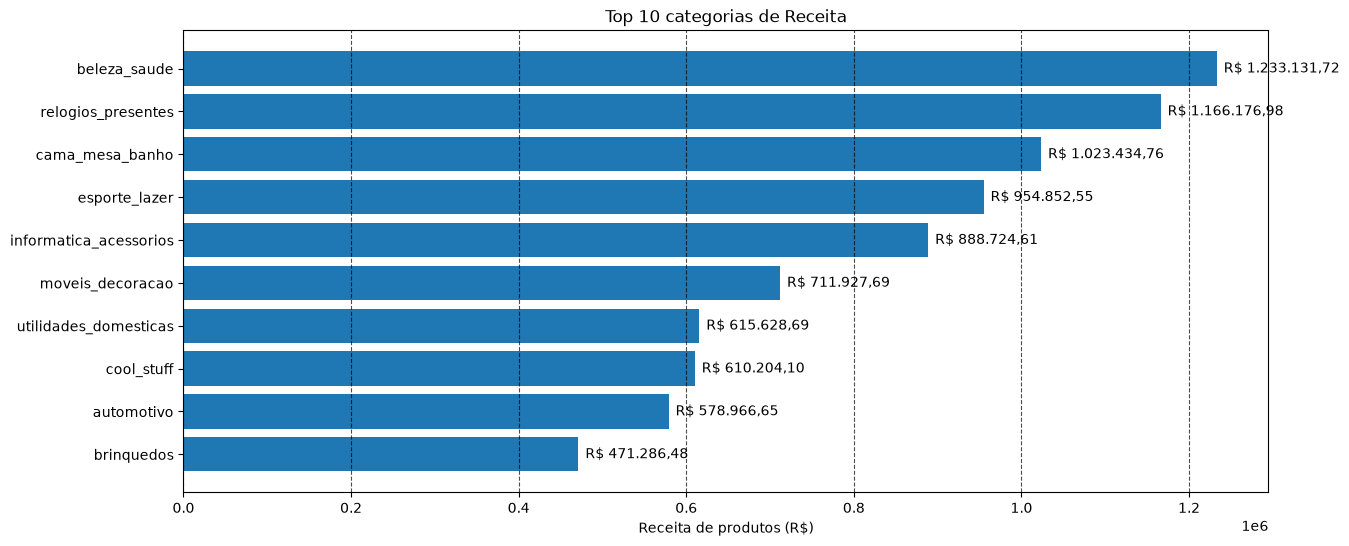

In [184]:
plt.figure(figsize=(14,6))
plt.title("Top 10 categorias de Receita")
plt.barh(top10_categorias.index, top10_categorias.values)
plt.gca().invert_yaxis()
for categoria, valor in zip(top10_categorias.index, top10_categorias.values):
    plt.annotate(
        text= formatar_valor(valor) ,
        xy = (valor, categoria),
        xytext=(5,0),
        textcoords='offset points',
        ha = 'left',
        va = 'center'
    )
plt.xlabel('Receita de produtos (R$)')
plt.grid(axis='x', linestyle = '--', alpha = 0.7, color='black')
plt.show()

#### Quanto as principais categorias representam da receita total de produtos?

In [185]:
receita_total_produtos = receitas_por_categorias.sum()
receita_10_maiores_categorias = top10_categorias.sum()
print(formatar_valor(receita_total_produtos))
print(formatar_valor(receita_10_maiores_categorias))

R$ 13.221.498,11
R$ 8.254.334,23


In [186]:

participacao_top10 = (receita_10_maiores_categorias / receita_total_produtos) * 100
print(f'participação das 10 maiores: {participacao_top10:,.2f}%'.replace('.', ','))

participação das 10 maiores: 62,43%


[np.float64(62.43115690314159), np.float64(37.56884309685841)]


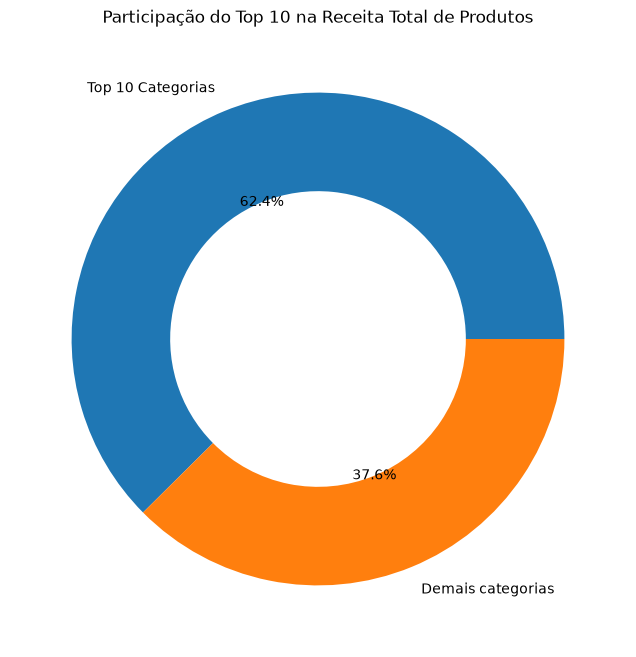

In [187]:
# Grafico de rosca

valores = [participacao_top10 , (100 - participacao_top10)]
rotulos = ['Top 10 Categorias', 'Demais categorias']
print(valores)

plt.figure(figsize=(8,8))
plt.title('Participação do Top 10 na Receita Total de Produtos')
plt.pie(
    valores,
    labels= rotulos,
    autopct='%.1f%%',
    wedgeprops={'width':0.4}
        )
plt.show()

#### Como a receita de produtos e a quantidade de pedidos entregues se distribuem pelos estados brasileiros?


In [188]:
consulta = 'select * from analytics.customers'

df_customers = pd.read_sql(consulta, con=engine)

df_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [189]:
print(df_customers.shape)
print(df_customers.info())

(99441, 5)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  str  
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: str(5)
memory usage: 3.8 MB
None


In [190]:
# Relacionar clientes às vendas

df_vendas_uf = pd.merge(df_vendas, df_customers[['customer_id', 'customer_state']],
                        on= 'customer_id', how='left', validate='many_to_one')

df_vendas_uf.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,ano_mes,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,2017-10,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,2018-07,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,2018-08,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,2017-11,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,2018-02,SP


In [191]:
df_vendas_uf.shape

(110197, 16)

In [192]:
# Verificar a correspondência dos estados

print(f'customer_states ausentes = {df_vendas_uf['customer_state'].isna().sum()}')
print(f'UF distintas = {df_vendas_uf['customer_state'].nunique()}')


customer_states ausentes = 0
UF distintas = 27


In [193]:
# Receita e quantidade de pedidos por UF

indicadores_uf = df_vendas_uf.groupby('customer_state').agg(

    receita_produtos = ('price', 'sum'),
    quantidade_pedidos = ('order_id', 'nunique')
)
indicadores_uf.sort_values(by='receita_produtos', ascending=False).head()
# indicadores_uf.sort_values(by='receita_produtos', ascending=False).sum()


,receita_produtos,quantidade_pedidos
customer_state,,
SP,5067633.16,40501
RJ,1759651.13,12350
MG,1552481.83,11354
RS,728897.47,5345
PR,666063.51,4923


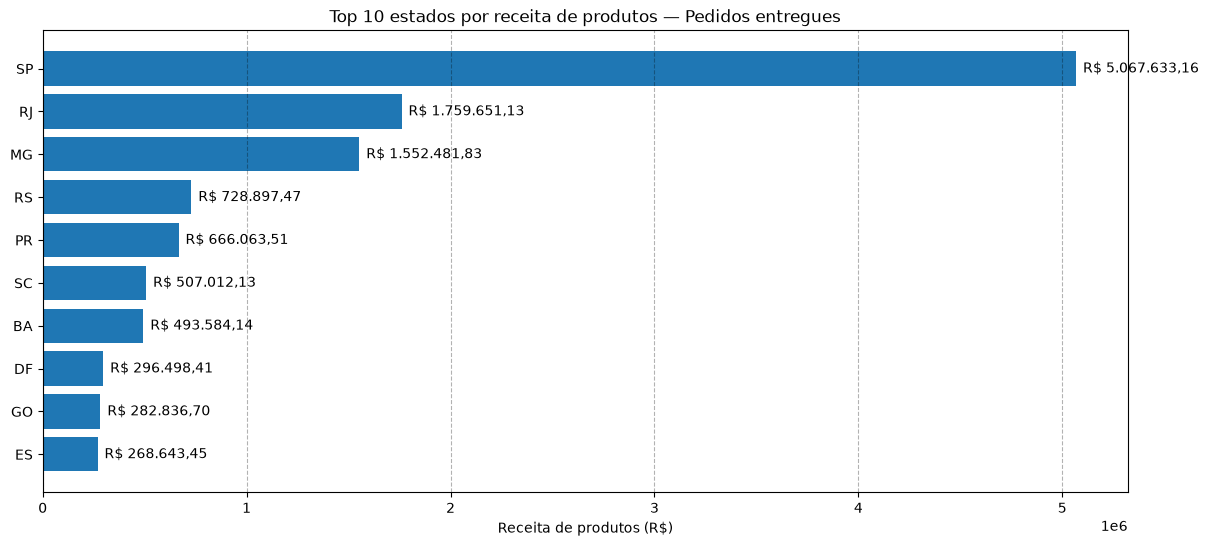

In [194]:
estados_receita_top10 = indicadores_uf.sort_values(by='receita_produtos', ascending=False).head(10)

plt.figure(figsize=(14,6))
plt.title("Top 10 estados por receita de produtos — Pedidos entregues")
plt.barh(estados_receita_top10.index, estados_receita_top10['receita_produtos'])
plt.gca().invert_yaxis()
for estado, valor in zip(estados_receita_top10.index, estados_receita_top10['receita_produtos']):
    plt.annotate(
        text= formatar_valor(valor) ,
        xy = (valor, estado),
        xytext=(5,0),
        textcoords='offset points',
        ha = 'left',
        va = 'center'
    )
plt.xlabel('Receita de produtos (R$)')
plt.grid(axis='x', linestyle = '--', alpha = 0.3, color='black')
plt.show()

### Tempo de entrega dos pedidos.

* Quanto tempo, em média, os pedidos da Olist levam para chegar aos clientes?

In [195]:
print(df_orders_delivered.dtypes)
print(f"Valores ausentes em 'order_purchase_timestamp': {df_orders_delivered['order_purchase_timestamp'].isna().sum()}")
print(f"Valores ausentes em 'order_delivered_customer_date': {df_orders_delivered['order_delivered_customer_date'].isna().sum()}")



order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object
Valores ausentes em 'order_purchase_timestamp': 0
Valores ausentes em 'order_delivered_customer_date': 8


In [196]:
# Valor ausente em order_delivered_customer_date
# df_orders_delivered[df_orders_delivered['order_delivered_customer_date'].isna()]

# Decisão: Vamos remover os pedidos que não possuem data de entrega do cliente, pois não é possível calcular 
# o tempo de entrega sem essa informação.
df_logistica = df_orders_delivered.dropna(subset=['order_delivered_customer_date','order_purchase_timestamp'],how='any')

df_logistica.shape


(96470, 8)

In [197]:
# tempo de entrega dos pedidos entregues
df_logistica['tempo_entrega_dias'] = (df_logistica['order_delivered_customer_date'] - df_logistica['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)  # Convertendo para dias

df_logistica.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,tempo_entrega_dias
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877


In [198]:
# print(f" Média de tempo de entrega: {formatar_valor(df_logistica['tempo_entrega_dias'].mean())} dias")
df_logistica['tempo_entrega_dias'].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: tempo_entrega_dias, dtype: float64

#### Histograma com tempo de entrega

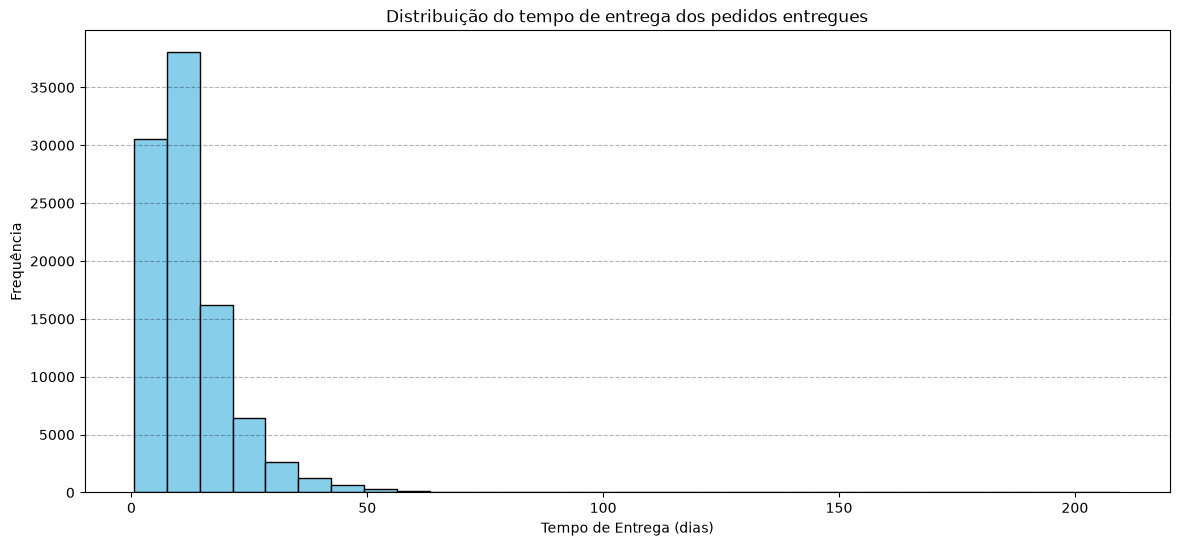

In [199]:
plt.figure(figsize=(14,6))
plt.title('Distribuição do tempo de entrega dos pedidos entregues')
plt.hist(df_logistica['tempo_entrega_dias'], bins=30, color='skyblue', edgecolor='black', )
plt.grid(axis='y', linestyle = '--', alpha = 0.3, color='black')
plt.xlabel('Tempo de Entrega (dias)')
plt.ylabel('Frequência')
plt.show()

* Os pedidos entregues apresentam tempo médio de aproximadamente 12,56 dias, com distribuição assimétrica à direita. A mediana inferior à média indica que entregas muito demoradas influenciam o indicador médio.

#### Qual percentual dos pedidos foi entregue após a data estimada pela Olist?

In [200]:
print(df_logistica['order_purchase_timestamp'].isna().sum())
df_logistica['order_purchase_timestamp'].dtype

0


dtype('<M8[us]')

In [201]:
df_logistica['entrega_atrasada'] = df_logistica['order_delivered_customer_date'].dt.normalize() > df_logistica['order_estimated_delivery_date'].dt.normalize()

# df_logistica['entrega_atrasada'].value_counts() / len(df_logistica['entrega_atrasada']) * 100
df_logistica['entrega_atrasada'].value_counts(normalize=True) * 100

entrega_atrasada
False    93.22691
True      6.77309
Name: proportion, dtype: float64

### Relação entre atrasos e avaliações

In [202]:
consulta = 'select * from analytics.order_reviews;'

df_reviews = pd.read_sql(consulta, con=engine)


In [203]:
print(df_reviews.info())
df_reviews.head()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  str           
 1   order_id                 99224 non-null  str           
 2   review_score             99224 non-null  int64         
 3   review_comment_title     99224 non-null  str           
 4   review_comment_message   99224 non-null  str           
 5   review_creation_date     99224 non-null  datetime64[us]
 6   review_answer_timestamp  99224 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(1), str(4)
memory usage: 5.3 MB
None


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,,,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,,,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,,,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


In [204]:
# Verificação de granularidade das avaliações de pedidos. Cada pedido deve ter apenas uma avaliação.

print(f'Número de pedidos com múltiplas avaliações: {df_reviews["order_id"].duplicated().sum()}')
print(f'Número de pedidos únicos: {df_reviews["order_id"].nunique()}')
print(f'Número de avaliações: {df_reviews["order_id"].count()}')

Número de pedidos com múltiplas avaliações: 551
Número de pedidos únicos: 98673
Número de avaliações: 99224


In [205]:
df_reviews_consolidado = df_reviews.groupby('order_id', as_index=False)['review_score'].mean()

print(df_reviews_consolidado.shape)

df_reviews_consolidado.duplicated(subset='order_id').sum()

(98673, 2)


np.int64(0)

In [209]:
display(df_logistica.head(5))
display(df_reviews_consolidado.head(5))


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,tempo_entrega_dias,entrega_atrasada
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,False


,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [210]:
df_atraso_reviews = pd.merge(df_logistica, df_reviews_consolidado, on='order_id', how='left', validate='one_to_one')
df_atraso_reviews.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,tempo_entrega_dias,entrega_atrasada,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,False,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,False,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,False,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,False,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,False,5.0


In [212]:
display(df_atraso_reviews.shape)
display(df_atraso_reviews['review_score'].isna().sum())

(96470, 11)

np.int64(646)

#### Comparar a satisfação dos clientes

* Os pedidos entregues com atraso recebem avaliações médias inferiores aos pedidos entregues no prazo?

In [222]:
indicadores_avaliação_atraso =df_atraso_reviews.groupby('entrega_atrasada').agg(
    quantidade=('review_score', 'count'),
    review_score=('review_score', 'mean')
)

indicadores_avaliação_atraso

,quantidade,review_score
entrega_atrasada,,
False,89443,4.290589
True,6381,2.271823


C:\Users\dyego\AppData\Local\Temp\ipykernel_22160\912301529.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Prazo', 'Atrasado'])


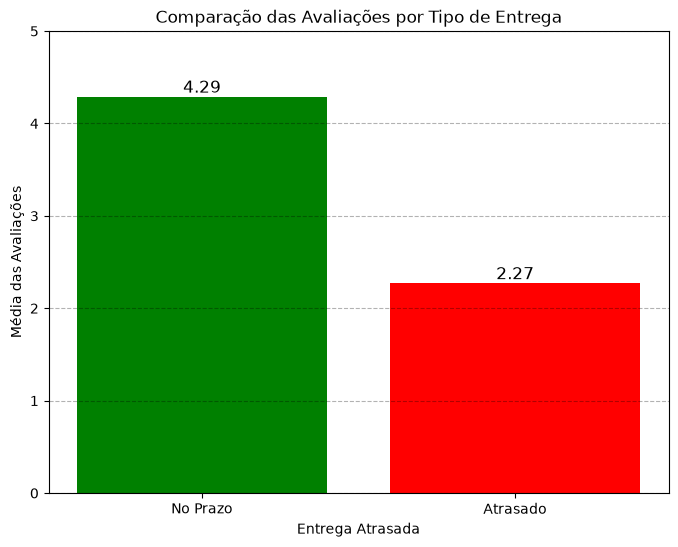

In [229]:
# Grafico de barras para comparar a média das avaliações de pedidos entregues no prazo e atrasados

fig, ax = plt.subplots(figsize=(8,6))
ax.bar(indicadores_avaliação_atraso.index.astype(str), indicadores_avaliação_atraso['review_score'], color=['green', 'red']) 
ax.set_xticklabels(['No Prazo', 'Atrasado'])
ax.set_ylim(0, 5)
ax.bar_label(ax.containers[0], fmt='%.2f', label_type='edge', fontsize=12)
plt.grid(axis='y', linestyle = '--', alpha = 0.3, color='black')   
plt.xlabel('Entrega Atrasada')
plt.ylabel('Média das Avaliações')
plt.title('Comparação das Avaliações por Tipo de Entrega')
plt.show()

### ConclusãoConclusões da Análise Exploratória de Dados (EDA)

#### 1. Visão comercial

A análise dos dados da Olist identificou **96.478 pedidos entregues**, totalizando **110.197 itens comercializados**. O faturamento dos produtos foi de **R$ 13.221.498,11**, enquanto o frete representou **R$ 2.198.275,64**, resultando em um valor total de **R$ 15.419.773,75**.

O **ticket médio por pedido foi de R$ 159,83**, considerando o valor dos produtos e do frete. Esses indicadores estabelecem uma visão geral do volume de operações e da movimentação financeira do e-commerce.

#### 2. Evolução temporal das vendas

A análise mensal permitiu identificar oscilações no faturamento ao longo do período estudado. **Novembro de 2017 apresentou o maior faturamento mensal de produtos, com R$ 987.765,37**, destacando-se como o principal pico de vendas identificado.

Os resultados demonstram a importância do acompanhamento temporal para identificar períodos de maior demanda e apoiar o planejamento comercial e operacional.

#### 3. Categorias de produtos e concentração de faturamento

A análise por categoria revelou que as **10 categorias de maior faturamento concentraram aproximadamente 62,43% da receita de produtos**.

Essa concentração evidencia a relevância de um grupo específico de categorias para o desempenho comercial da plataforma. O resultado pode contribuir para decisões relacionadas à gestão de portfólio, estoque e estratégias comerciais.

#### 4. Distribuição geográfica das vendas

As vendas apresentaram concentração significativa na região Sudeste, especialmente nos estados de **São Paulo, Rio de Janeiro e Minas Gerais**.

Os maiores faturamentos de produtos foram registrados em:

- **São Paulo:** R$ 5.067.633,16.
- **Rio de Janeiro:** R$ 1.759.651,13.
- **Minas Gerais:** R$ 1.552.481,83.

São Paulo também apresentou o maior volume de pedidos entregues, com **40.501 pedidos**, destacando-se como o principal mercado consumidor da base analisada.

Essa distribuição reforça a importância da análise regional para o planejamento logístico e a definição de estratégias de expansão comercial.

#### 5. Desempenho logístico

A análise logística considerou **96.470 pedidos entregues** com informações válidas de entrega.

O tempo médio entre a compra e o recebimento foi de **12,56 dias**, enquanto a mediana foi de **10,22 dias**, indicando uma distribuição assimétrica à direita, influenciada por entregas com prazos mais longos.

Quanto à pontualidade, foram identificados:

- **89.936 pedidos entregues no prazo:** 93,23%.
- **6.534 pedidos entregues com atraso:** 6,77%.

A taxa de atraso foi calculada considerando como atrasados os pedidos entregues após o dia previsto, independentemente do horário.

Os resultados indicam que a maioria das entregas ocorreu dentro do prazo estimado, embora exista uma parcela de pedidos com atrasos que merece atenção operacional.

#### 6. Relação entre atrasos e satisfação dos clientes

A análise das avaliações considerou **95.824 pedidos com notas disponíveis**, após a consolidação de múltiplas avaliações por pedido.

Os resultados demonstraram uma diferença expressiva entre as avaliações médias:

- **Pedidos entregues no prazo:** nota média de 4,29.
- **Pedidos entregues com atraso:** nota média de 2,27.

A diferença de aproximadamente **2,02 pontos**, em uma escala de 1 a 5, evidencia uma associação relevante entre atrasos logísticos e avaliações inferiores.

Embora essa relação não permita estabelecer causalidade, os resultados sugerem que a pontualidade das entregas é um fator importante a ser considerado nas estratégias de melhoria da experiência do cliente.

#### 7. Considerações finais

A análise exploratória permitiu compreender o comportamento comercial, a distribuição geográfica, o desempenho logístico e os padrões de avaliação dos clientes da Olist.

Os principais resultados apontam para três aspectos estratégicos:

1. **Concentração comercial:** determinadas categorias de produtos e regiões geográficas representam parcelas relevantes do faturamento.
2. **Eficiência logística:** a maioria dos pedidos é entregue dentro do prazo, mas os atrasos identificados representam uma oportunidade de melhoria operacional.
3. **Experiência do cliente:** pedidos atrasados apresentam avaliações médias consideravelmente inferiores às dos pedidos entregues no prazo.

Os indicadores e resultados obtidos constituem a base analítica para o desenvolvimento de um **dashboard no Power BI**, com foco no monitoramento de desempenho comercial, distribuição geográfica, eficiência logística e satisfação dos clientes.

A etapa de EDA Python é, portanto, considerada concluída dentro do escopo estabelecido para o projeto.